In [1]:
%pip install matplotlib numpy tensorflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random
import warnings
from tensorflow import keras
from tensorflow.keras import layers

I0000 00:00:1794693694.969381   17543 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794693695.498890   17543 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794693697.408024   17543 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
data=np.load('mnist.npz')
x_train,y_train=data['x_train'],data['y_train']
x_test,y_test=data['x_test'],data['y_test']
print(x_train.shape)

(60000, 28, 28)


In [6]:
m,n=np.max(x_train),np.min(x_train)
nor=m-n
print(f"Max pixel value {m}")
print(f"Min pixel value {n}")
x_train,x_test=x_train/nor,x_test/nor

Max pixel value 1.0
Min pixel value 0.0


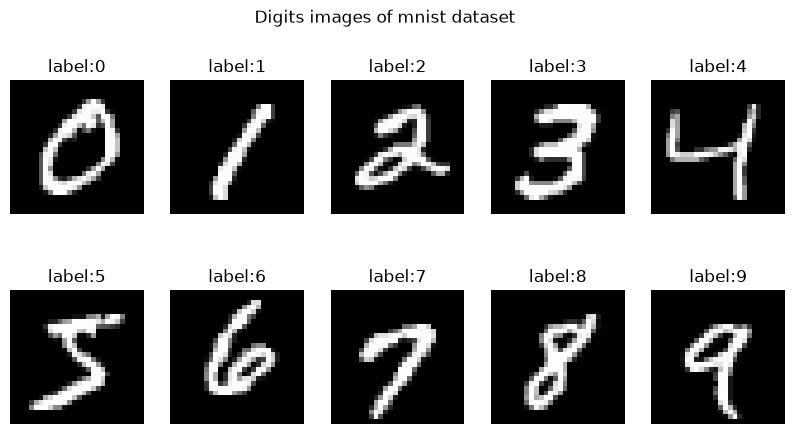

In [9]:
unique_labels,idx=np.unique(y_train,return_index=True)
fig,ax=plt.subplots(2,5,figsize=(10,5))
for i,label in enumerate(unique_labels):
    ax.flat[i].imshow(x_train[idx[i]],cmap='gray')
    ax.flat[i].set_title(f"label:{label}")
    ax.flat[i].axis("off")
plt.suptitle("Digits images of mnist dataset")
plt.show()

In [14]:
model1=keras.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(256,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64,activation='relu'),
    layers.Dense(10,activation='softmax')
                 ])

E0000 00:00:1794696204.270665   17543 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [22]:
model1.compile(optimizer=keras.optimizers.SGD(learning_rate=0.001),
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy']
              )
            

In [23]:
early_stopping=keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [51]:
history1=model1.fit(x_train,
                    y_train,
                    batch_size=32,
                    validation_split=0.2,
                    callbacks=[early_stopping],
                    verbose=2,
                    epochs=10
                   )

Epoch 1/10
1500/1500 - 5s - 4ms/step - accuracy: 0.8943 - loss: 0.3585 - val_accuracy: 0.9334 - val_loss: 0.2260
Epoch 2/10
1500/1500 - 5s - 3ms/step - accuracy: 0.9172 - loss: 0.2808 - val_accuracy: 0.9457 - val_loss: 0.1888
Epoch 3/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9305 - loss: 0.2354 - val_accuracy: 0.9531 - val_loss: 0.1621
Epoch 4/10
1500/1500 - 6s - 4ms/step - accuracy: 0.9375 - loss: 0.2096 - val_accuracy: 0.9580 - val_loss: 0.1469
Epoch 5/10
1500/1500 - 6s - 4ms/step - accuracy: 0.9442 - loss: 0.1827 - val_accuracy: 0.9607 - val_loss: 0.1342
Epoch 6/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9496 - loss: 0.1693 - val_accuracy: 0.9632 - val_loss: 0.1244
Epoch 7/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9545 - loss: 0.1540 - val_accuracy: 0.9650 - val_loss: 0.1165
Epoch 8/10
1500/1500 - 6s - 4ms/step - accuracy: 0.9577 - loss: 0.1413 - val_accuracy: 0.9660 - val_loss: 0.1105
Epoch 9/10
1500/1500 - 6s - 4ms/step - accuracy: 0.9616 - loss: 0.1303 - val_accuracy: 0.9674 - 

In [33]:
loss1,acc1=model1.evaluate(x_test,y_test,verbose=2)
print(f"Model 1 test accuracy {acc1*100:.2f}%")

313/313 - 1s - 4ms/step - accuracy: 0.9149 - loss: 0.2984
Model 1 test accuracy 91.49%


In [34]:
model2=keras.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(256,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64,activation='relu'),
    layers.Dense(10,activation='softmax')
                 ])

In [35]:
model2.compile(optimizer=keras.optimizers.SGD(learning_rate=0.005),
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy']
              )
            

In [52]:
history2=model2.fit(x_train,
                    y_train,
                    batch_size=32,
                    validation_split=0.2,
                    callbacks=[early_stopping],
                    verbose=2,
                    epochs=10
                   )

Epoch 1/10
1500/1500 - 6s - 4ms/step - accuracy: 0.8439 - loss: 0.5207 - val_accuracy: 0.9098 - val_loss: 0.3198
Epoch 2/10
1500/1500 - 4s - 3ms/step - accuracy: 0.8819 - loss: 0.4024 - val_accuracy: 0.9255 - val_loss: 0.2646
Epoch 3/10
1500/1500 - 5s - 3ms/step - accuracy: 0.9001 - loss: 0.3402 - val_accuracy: 0.9339 - val_loss: 0.2329
Epoch 4/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9099 - loss: 0.3031 - val_accuracy: 0.9402 - val_loss: 0.2075
Epoch 5/10
1500/1500 - 6s - 4ms/step - accuracy: 0.9199 - loss: 0.2703 - val_accuracy: 0.9452 - val_loss: 0.1904
Epoch 6/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9253 - loss: 0.2494 - val_accuracy: 0.9498 - val_loss: 0.1753
Epoch 7/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9329 - loss: 0.2275 - val_accuracy: 0.9527 - val_loss: 0.1651
Epoch 8/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9368 - loss: 0.2116 - val_accuracy: 0.9557 - val_loss: 0.1545
Epoch 9/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9408 - loss: 0.2003 - val_accuracy: 0.9572 - 

In [37]:
loss2,acc2=model2.evaluate(x_test,y_test,verbose=2)
print(f"Model 2 test accuracy {acc2*100:.2f}%")

313/313 - 1s - 2ms/step - accuracy: 0.8714 - loss: 0.4831
Model 2 test accuracy 87.14%


In [39]:
model3=keras.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(256,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64,activation='relu'),
    layers.Dense(10,activation='softmax')
                 ])

In [40]:
model3.compile(optimizer=keras.optimizers.SGD(learning_rate=0.005),
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy']
              )
            

In [53]:
history3=model3.fit(x_train,
                    y_train,
                    batch_size=32,
                    validation_split=0.2,
                    callbacks=[early_stopping],
                    verbose=2,
                    epochs=10
                   )

Epoch 1/10
1500/1500 - 4s - 3ms/step - accuracy: 0.8420 - loss: 0.5238 - val_accuracy: 0.9103 - val_loss: 0.3180
Epoch 2/10
1500/1500 - 4s - 3ms/step - accuracy: 0.8799 - loss: 0.4037 - val_accuracy: 0.9229 - val_loss: 0.2661
Epoch 3/10
1500/1500 - 4s - 3ms/step - accuracy: 0.8979 - loss: 0.3456 - val_accuracy: 0.9327 - val_loss: 0.2331
Epoch 4/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9104 - loss: 0.3048 - val_accuracy: 0.9383 - val_loss: 0.2088
Epoch 5/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9180 - loss: 0.2764 - val_accuracy: 0.9441 - val_loss: 0.1894
Epoch 6/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9267 - loss: 0.2513 - val_accuracy: 0.9480 - val_loss: 0.1747
Epoch 7/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9319 - loss: 0.2320 - val_accuracy: 0.9521 - val_loss: 0.1640
Epoch 8/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9367 - loss: 0.2169 - val_accuracy: 0.9548 - val_loss: 0.1534
Epoch 9/10
1500/1500 - 4s - 3ms/step - accuracy: 0.9390 - loss: 0.2026 - val_accuracy: 0.9571 - 

In [42]:
loss3,acc3=model3.evaluate(x_test,y_test,verbose=2)
print(f"Model 3 test accuracy {acc3*100:.2f}%")

313/313 - 1s - 3ms/step - accuracy: 0.8711 - loss: 0.4772
Model 3 test accuracy 87.11%


In [43]:
print("\nFinal Test Accuracy Comparison:")
print(f"Learning Rate 0.001 : {acc1 * 100:.2f}%")
print(f"Learning Rate 0.005 : {acc2 * 100:.2f}%")
print(f"Learning Rate 0.01  : {acc3 * 100:.2f}%")


Final Test Accuracy Comparison:
Learning Rate 0.001 : 91.49%
Learning Rate 0.005 : 87.14%
Learning Rate 0.01  : 87.11%


Enter image index between 0-9999 786


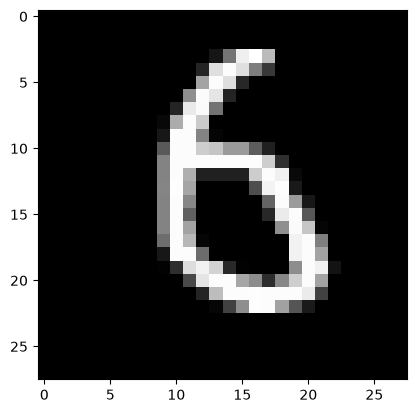

predicted image is  6
actual digit is  6


In [46]:
img_index=int(input('Enter image index between 0-9999'))
plt.imshow(x_test[img_index],cmap='gray')
plt.show()
prediction=model1.predict(x_test[img_index].reshape(1,28,28),verbose=0)
print(f"predicted image is ", np.argmax(prediction))
print(f"actual digit is ",y_test[img_index])

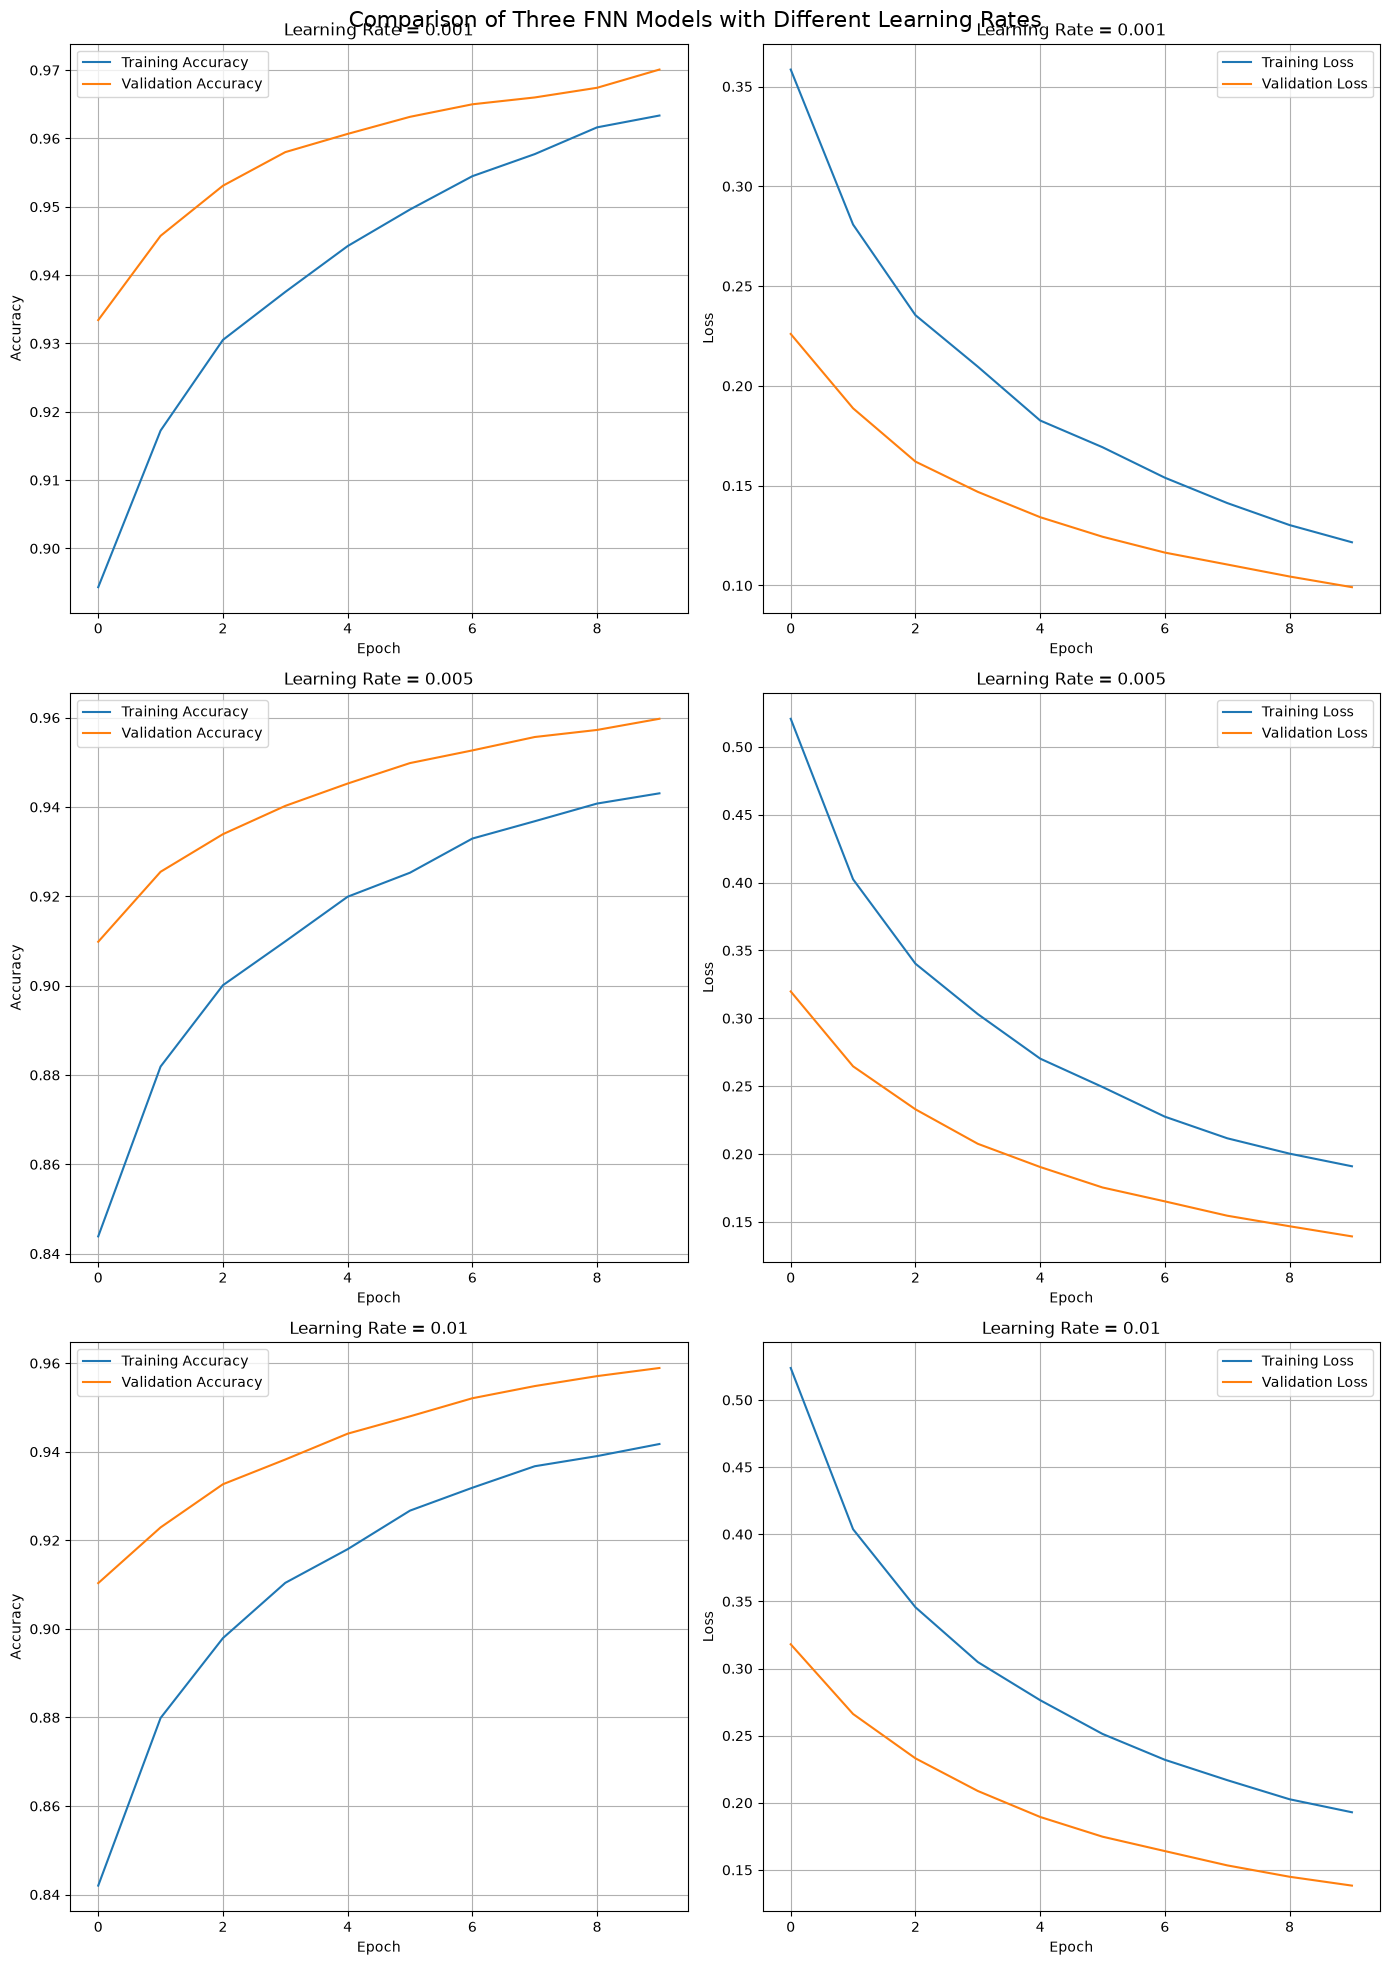

In [54]:
histories = [history1, history2, history3]
learning_rates = [0.001, 0.005, 0.01]

fig, axes = plt.subplots(3, 2, figsize=(14, 20))

for i, history in enumerate(histories):
    axes[i, 0].plot(history.history['accuracy'], label='Training Accuracy')
    axes[i, 0].plot(history.history['val_accuracy'], label='Validation Accuracy')
    axes[i, 0].set_title(f'Learning Rate = {learning_rates[i]}')
    axes[i, 0].set_xlabel('Epoch')
    axes[i, 0].set_ylabel('Accuracy')
    axes[i, 0].legend()
    axes[i, 0].grid(True)

    axes[i, 1].plot(history.history['loss'], label='Training Loss')
    axes[i, 1].plot(history.history['val_loss'], label='Validation Loss')
    axes[i, 1].set_title(f'Learning Rate = {learning_rates[i]}')
    axes[i, 1].set_xlabel('Epoch')
    axes[i, 1].set_ylabel('Loss')
    axes[i, 1].legend()
    axes[i, 1].grid(True)

plt.suptitle('Comparison of Three FNN Models with Different Learning Rates', fontsize=16)
plt.tight_layout()
plt.show()

In [49]:
for h in histories:
    print({k: v for k, v in h.history.items()})

{'accuracy': [0.875124990940094], 'loss': [0.42035582661628723], 'val_accuracy': [0.9144999980926514], 'val_loss': [0.2971084415912628]}
{'accuracy': [0.6121249794960022], 'loss': [1.2611839771270752], 'val_accuracy': [0.8760833144187927], 'val_loss': [0.4714221954345703]}
{'accuracy': [0.612666666507721], 'loss': [1.2329061031341553], 'val_accuracy': [0.8777499794960022], 'val_loss': [0.46643421053886414]}
